# Course 1 - Modul 3: Exploratory Data Analysis & Advanced Feature Engineering
**Mata Kuliah**: Data Mining  
**Kode Modul**: `c1-m3` (Course 1 - Module 3)  
**Topik Utama**: Analisis Eksplorasi Data (EDA), Visualisasi Matplotlib/Seaborn/Pandas, Transformasi Variabel & Skewness, Encoding Kategorikal, Komparasi Scaler (Standard, MinMax, Robust), dan Seleksi Fitur.

---

## 1. Pendahuluan & Ringkasan Pembelajaran
Setelah data dibersihkan di Modul 2, tahap selanjutnya dalam pipeline Data Mining adalah **Exploratory Data Analysis (EDA)** dan **Feature Engineering**:
1. **Exploratory Data Analysis (EDA)**: Menjelajahi struktur data secara statistik dan visual untuk menemukan pola, relasi, anomali, dan memahami distribusi underlying feature.
2. **Variable Transformations**: Mengatasi kemiringan (*skewness*) data untuk memenuhi asumsi normalitas model parametrik melalui transformasi Log, Square Root, Box-Cox/Yeo-Johnson, serta menangkap relasi non-linear melalui *Polynomial Features*.
3. **Feature Encoding**: Mengubah data kategorikal nominal (*One-Hot Encoding*) dan ordinal (*Ordinal Encoding*), serta mengatasi *high-cardinality* dengan *Target/Frequency Encoding*.
4. **Feature Scaling**: Menyelaraskan skala fitur kontinu agar algoritma berbasis jarak (KNN, SVM, K-Means) dan algoritma berbasis gradient tidak terdistorsi (ilustrasi: perbedaan skala tahun vs detik bedah pada transkrip perkuliahan).
5. **Feature Selection**: Memilih subset fitur paling informatif melalui *Filter Methods* (Correlation, Mutual Information, ANOVA F-test) dan *Embedded Methods* (Random Forest Feature Importance).


## 2. Exploratory Data Analysis (EDA) & Visualisasi Mendalam

Kita mulai dengan memuat dataset hasil pembersihan dari Modul 2 (`data/telco_churn_cleaned_m2.csv`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 5)

# Memuat data hasil pembersihan Modul 2
df = pd.read_csv('data/telco_churn_cleaned_m2.csv')
print(f"Data berhasil dimuat. Dimensi: {df.shape}")
display(df.head())


Data berhasil dimuat. Dimensi: (1200, 17)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,1001-ABCD,Male,0,No,No,43,Yes,No,Fiber optic,No,No internet service,Month-to-month,No,Credit card (automatic),75.01,3228.52,Yes
1,1002-ABCD,Female,0,No,No,72,Yes,No,Fiber optic,No internet service,No internet service,Month-to-month,No,Electronic check,59.50,4287.89,Yes
2,1003-ABCD,Male,0,Yes,Yes,72,Yes,No,Fiber optic,Yes,No internet service,Month-to-month,No,Mailed check,65.23,4688.51,Yes
3,1004-ABCD,Male,0,Yes,No,42,Yes,No,No,No,No,One year,Yes,Bank transfer (automatic),27.69,1164.42,No
4,1005-ABCD,Male,0,Yes,No,26,Yes,No phone service,Fiber optic,Yes,No,Month-to-month,Yes,Bank transfer (automatic),65.92,1704.52,Yes


In [2]:
# 2.1 Statistik Deskriptif & Skewness
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
stats_summary = df[numeric_cols].describe().T
stats_summary['skewness'] = df[numeric_cols].skew()
stats_summary['kurtosis'] = df[numeric_cols].kurtosis()

print("Statistik Deskriptif & Ukuran Bentuk Distribusi:")
display(stats_summary.round(2))


Statistik Deskriptif & Ukuran Bentuk Distribusi:


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
tenure,1200.0,36.48,20.61,1.00,18.00,37.00,54.00,72.00,0.00,-1.19
MonthlyCharges,1200.0,62.95,19.47,18.25,49.81,65.18,78.23,108.16,-0.40,-0.62
TotalCharges,1200.0,2304.30,1550.74,21.38,990.49,2053.10,3435.86,6950.00,0.55,-0.54


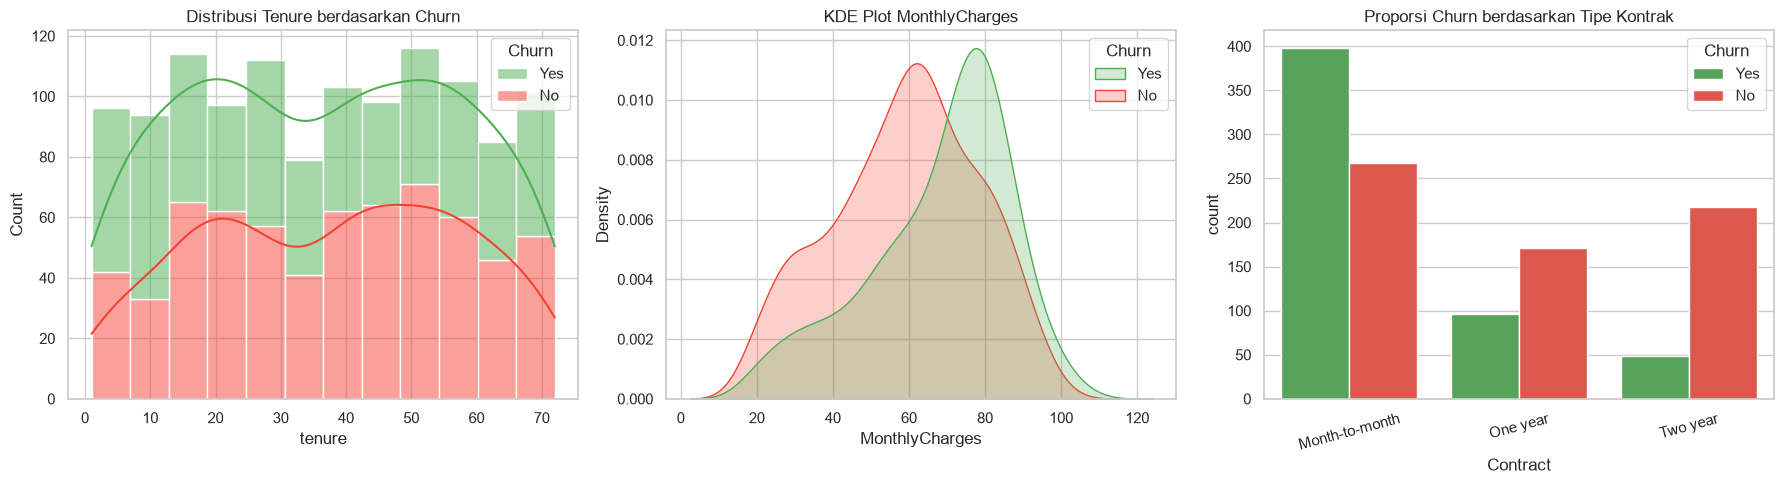

In [3]:
# 2.2 Visualisasi Univariate & Bivariate dengan Seaborn & Matplotlib
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribusi Tenure terhadap Churn
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', kde=True, ax=axes[0], palette=['#4CAF50', '#F44336'])
axes[0].set_title('Distribusi Tenure berdasarkan Churn')

# Distribusi MonthlyCharges terhadap Churn
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, ax=axes[1], palette=['#4CAF50', '#F44336'])
axes[1].set_title('KDE Plot MonthlyCharges')

# Hubungan Kontrak dengan Churn (Countplot)
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[2], palette=['#4CAF50', '#F44336'])
axes[2].set_title('Proporsi Churn berdasarkan Tipe Kontrak')
axes[2].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()


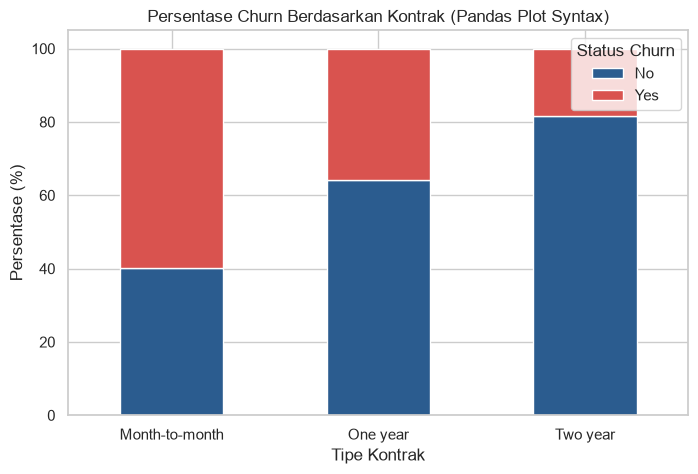

In [4]:
# 2.3 Syntax Plotting Pandas (Groupby Analysis)
# Sesuai materi c1-m3(2).txt: Menggunakan Panda syntax untuk plotting
churn_by_contract = df.groupby(['Contract', 'Churn']).size().unstack()
churn_by_contract_pct = churn_by_contract.div(churn_by_contract.sum(axis=1), axis=0) * 100

churn_by_contract_pct.plot(kind='bar', stacked=True, figsize=(8, 5), color=['#2b5c8f', '#d9534f'])
plt.title('Persentase Churn Berdasarkan Kontrak (Pandas Plot Syntax)', fontsize=12)
plt.ylabel('Persentase (%)')
plt.xlabel('Tipe Kontrak')
plt.legend(title='Status Churn')
plt.xticks(rotation=0)
plt.show()


## 3. Variable Transformations & Penanganan Skewness

Banyak model parametrik (seperti regresi linier dan logistik) mengasumsikan residu terdistribusi normal. Variabel yang *skewed* (menceng kanan/kiri) dapat mendistorsi estimasi koefisien.
Kita mendemonstrasikan:
1. **Log Transformation**: $x' = \log(1 + x)$
2. **Power Transformation (Yeo-Johnson / Box-Cox)**: Menstabilkan varians dan mendekatkan distribusi ke kurva lonceng normal.
3. **Polynomial Features**: Menangkap hubungan non-linear ($x_1^2, x_1 x_2, x_2^2$).


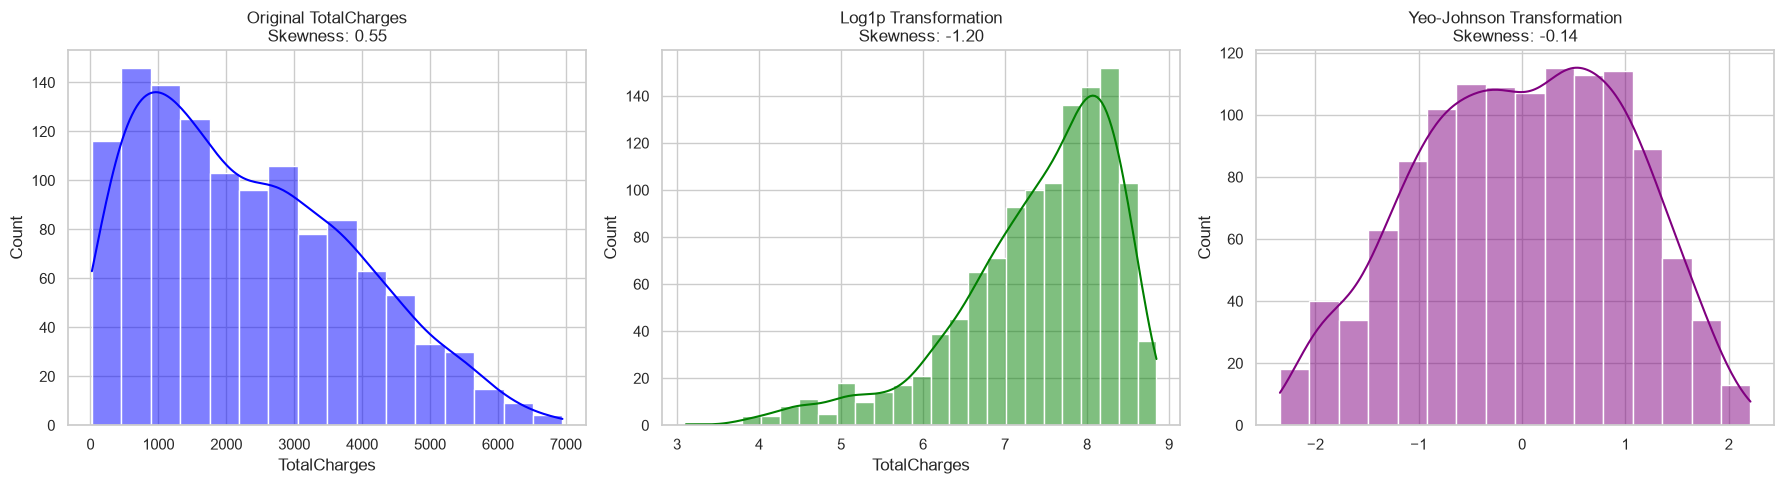

In [5]:
from sklearn.preprocessing import PowerTransformer, PolynomialFeatures

# Analisis Skewness TotalCharges sebelum dan setelah transformasi
original_tc = df['TotalCharges']
log_tc = np.log1p(original_tc)

pt = PowerTransformer(method='yeo-johnson')
yj_tc = pt.fit_transform(original_tc.values.reshape(-1, 1)).flatten()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(original_tc, kde=True, ax=axes[0], color='blue')
axes[0].set_title(f"Original TotalCharges\nSkewness: {original_tc.skew():.2f}")

sns.histplot(log_tc, kde=True, ax=axes[1], color='green')
axes[1].set_title(f"Log1p Transformation\nSkewness: {pd.Series(log_tc).skew():.2f}")

sns.histplot(yj_tc, kde=True, ax=axes[2], color='purple')
axes[2].set_title(f"Yeo-Johnson Transformation\nSkewness: {pd.Series(yj_tc).skew():.2f}")

plt.tight_layout()
plt.show()


In [6]:
# 3.2 Pembuatan Polynomial Features (Non-linear Interaction)
# Sesuai c1-m3(4).txt: Menangkap efek interaksi x1 * x2 dan efek polinomial x^2
poly = PolynomialFeatures(degree=2, include_bias=False)
sample_poly_data = df[['tenure', 'MonthlyCharges']]
poly_features = poly.fit_transform(sample_poly_data)
poly_feature_names = poly.get_feature_names_out(['tenure', 'MonthlyCharges'])

df_poly = pd.DataFrame(poly_features, columns=poly_feature_names)
print(f"Fitur asli: {sample_poly_data.shape[1]} -> Fitur Polinomial: {df_poly.shape[1]}")
print("\nContoh Fitur Polinomial yang Dihasilkan:")
display(df_poly.head(3))


Fitur asli: 2 -> Fitur Polinomial: 5

Contoh Fitur Polinomial yang Dihasilkan:


,tenure,MonthlyCharges,tenure^2,tenure MonthlyCharges,MonthlyCharges^2
0,43.0,75.01,1849.0,3225.43,5626.5001
1,72.0,59.50,5184.0,4284.00,3540.2500
2,72.0,65.23,5184.0,4696.56,4254.9529


## 4. Categorical Feature Encoding

Model matematika dalam data mining hanya dapat mengolah nilai numerik. Kita menggunakan dua strategi encoding utama:
- **One-Hot Encoding**: Untuk fitur kategorikal nominal tanpa urutan (*gender, InternetService, PaymentMethod*).
- **Ordinal Encoding**: Untuk fitur kategorikal yang memiliki tingkatan alami (*Contract: Month-to-month < One year < Two year*).


In [7]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# 4.1 Ordinal Encoding untuk Contract
contract_order = [['Month-to-month', 'One year', 'Two year']]
ord_encoder = OrdinalEncoder(categories=contract_order)
df['Contract_Ordinal'] = ord_encoder.fit_transform(df[['Contract']])

print("Pemetaan Ordinal Contract:")
display(df[['Contract', 'Contract_Ordinal']].drop_duplicates().sort_values('Contract_Ordinal'))


Pemetaan Ordinal Contract:


,Contract,Contract_Ordinal
0,Month-to-month,0.0
3,One year,1.0
9,Two year,2.0


In [8]:
# 4.2 One-Hot Encoding untuk Fitur Nominal
nominal_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 
                'InternetService', 'OnlineSecurity', 'TechSupport', 'PaperlessBilling', 'PaymentMethod']

df_encoded = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)
# Encode target variable Churn (Yes: 1, No: 0)
df_encoded['Churn'] = (df_encoded['Churn'] == 'Yes').astype(int)

print(f"Jumlah kolom sebelum OHE: {df.shape[1]} -> Setelah OHE: {df_encoded.shape[1]}")
print("\nKolom-kolom baru hasil One-Hot Encoding:")
print([col for col in df_encoded.columns if any(prefix in col for prefix in ['InternetService', 'PaymentMethod'])][:8])


Jumlah kolom sebelum OHE: 18 -> Setelah OHE: 24

Kolom-kolom baru hasil One-Hot Encoding:
['InternetService_Fiber optic', 'InternetService_No', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


## 5. Feature Scaling: Komparasi StandardScaler vs MinMaxScaler vs RobustScaler

Mengapa penskalaan krusial? Sebagaimana dibahas pada materi kuliah (`c1-m3(6).txt`), algoritma berbasis jarak (seperti KNN atau KMeans) akan didominasi oleh variabel berorde besar jika unitnya tidak setara (misal: usia dalam detik vs jumlah operasi bedah).
Tiga scaler utama yang kita komparasikan:
1. **StandardScaler**: Mengubah mean menjadi 0 dan standar deviasi menjadi 1 ($z = \frac{x - \mu}{\sigma}$). Sensitif terhadap outlier.
2. **MinMaxScaler**: Menekan semua nilai ke rentang $[0, 1]$ ($x' = \frac{x - x_{min}}{x_{max} - x_{min}}$). Sangat rentan terhadap outlier ekstrem.
3. **RobustScaler**: Menggunakan median dan IQR ($x' = \frac{x - \text{median}}{\text{IQR}}$). Paling tahan terhadap pencilan (*outliers*).


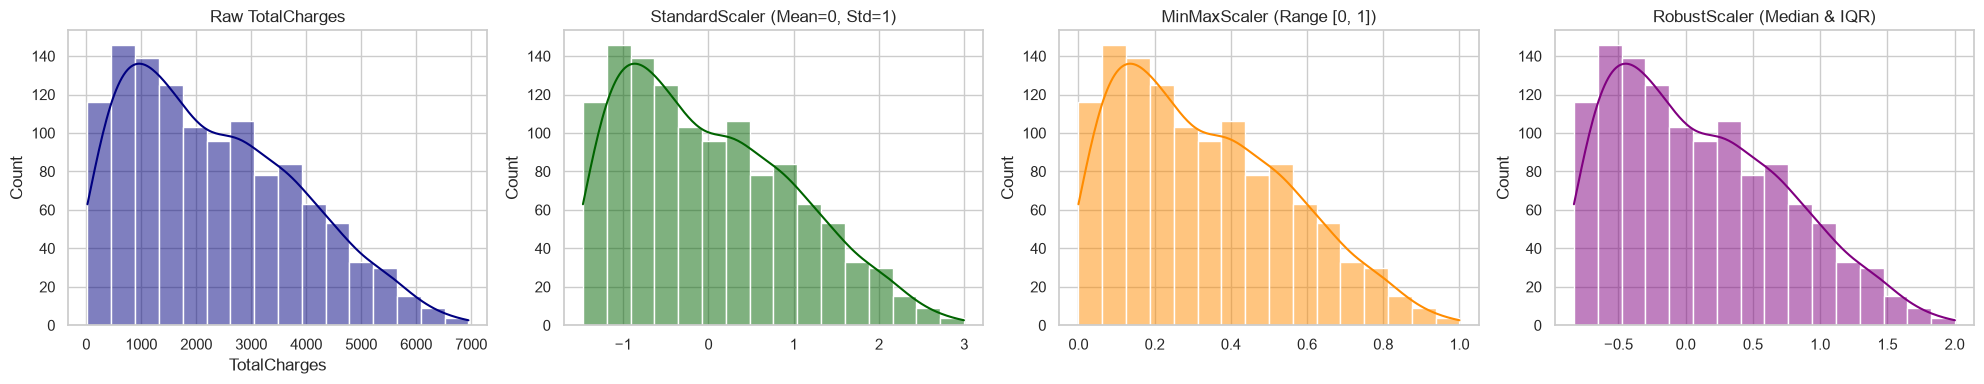

In [9]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler_std = StandardScaler()
scaler_minmax = MinMaxScaler()
scaler_robust = RobustScaler()

std_scaled = scaler_std.fit_transform(df[scale_cols])
minmax_scaled = scaler_minmax.fit_transform(df[scale_cols])
robust_scaled = scaler_robust.fit_transform(df[scale_cols])

# Perbandingan visual dampak scaler pada kolom TotalCharges
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

sns.histplot(df['TotalCharges'], kde=True, ax=axes[0], color='navy')
axes[0].set_title('Raw TotalCharges')

sns.histplot(std_scaled[:, 2], kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title('StandardScaler (Mean=0, Std=1)')

sns.histplot(minmax_scaled[:, 2], kde=True, ax=axes[2], color='darkorange')
axes[2].set_title('MinMaxScaler (Range [0, 1])')

sns.histplot(robust_scaled[:, 2], kde=True, ax=axes[3], color='purple')
axes[3].set_title('RobustScaler (Median & IQR)')

plt.tight_layout()
plt.show()


## 6. Feature Selection (Seleksi Fitur)

Memilih subset fitur terbaik mengurangi dimensi (*curse of dimensionality*), mencegah overfitting, dan mempercepat waktu komputasi.
Kita menerapkan:
1. **Filter Method (Mutual Information)**: Mengukur ketergantungan non-linear antar variabel fitur dan target Churn.
2. **Embedded Method (Random Forest Importance)**: Mengukur penurunan ketidakmurnian (*mean decrease in impurity*) dari pohon keputusan.


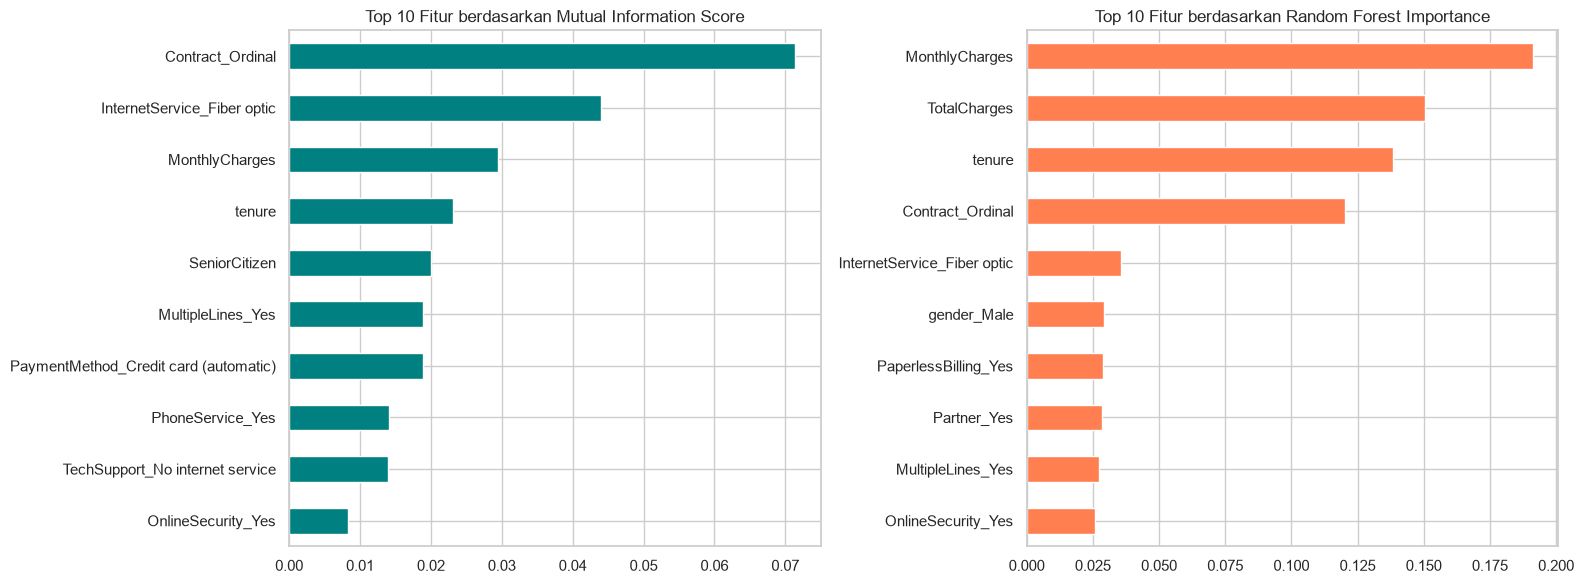

In [10]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

X = df_encoded.drop(columns=['customerID', 'Contract', 'Churn'])
y = df_encoded['Churn']

# 1. Mutual Information Score
mi_scores = mutual_info_classif(X, y, random_state=42)
mi_series = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)

# 2. Random Forest Feature Importance
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Visualisasi Top 10 Fitur Terpenting
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mi_series.head(10).plot(kind='barh', ax=axes[0], color='teal')
axes[0].set_title('Top 10 Fitur berdasarkan Mutual Information Score')
axes[0].invert_yaxis()

rf_importance.head(10).plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Top 10 Fitur berdasarkan Random Forest Importance')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


In [11]:
# Menyimpan dataset siap model ke data/telco_churn_featured_m3.csv
df_encoded.to_csv('data/telco_churn_featured_m3.csv', index=False)
print("Dataset hasil Feature Engineering berhasil disimpan ke 'data/telco_churn_featured_m3.csv'!")
print(f"Dimensi dataset siap pemodelan: {df_encoded.shape}")


Dataset hasil Feature Engineering berhasil disimpan ke 'data/telco_churn_featured_m3.csv'!
Dimensi dataset siap pemodelan: (1200, 24)


### Ringkasan Capaian Modul 3:
1. **Exploratory Data Analysis**: Mengidentifikasi bahwa pelanggan dengan kontrak *Month-to-month* dan *Fiber optic* memiliki churn rate jauh lebih tinggi.
2. **Skewness Remediation**: Membuktikan transformasi Yeo-Johnson dan Log sukses mereduksi kemiringan distribusi.
3. **Encoding & Polynomials**: Menerapkan One-Hot Encoding dan interaksi polinomial untuk memperkaya representasi data.
4. **Scaler Benchmark**: Menunjukkan karakteristik StandardScaler vs MinMaxScaler vs RobustScaler.
5. **Feature Selection**: Menemukan bahwa `Contract`, `tenure`, `TotalCharges`, dan `MonthlyCharges` adalah prediktor churn paling dominan.
6. **Langkah Berikutnya**: Kita melangkah ke **Course 1 Modul 4 (`c1-m4`)** untuk pengujian hipotesis statistik dan membangun model prediksi terbaik!
